In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

In [6]:
csv_dir = Path("outputs/recoil_heatings_results")
csv_files = sorted(csv_dir.glob("recoil_heating_summary_case_*.csv"))

comparison_data = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

# Compare theoretical data against the proposed methods

In [ ]:
theoretical_limit_data = comparison_data.loc[comparison_data["long_axis_nm"]<=100, ["long_axis_nm", "militaru_S_tau_tau_N2_m2_per_Hz", "derivative_S_tau_tau_y_N2_m2_per_Hz", "spectral_S_tau_tau_y_N2_m2_per_Hz"]]
theoretical_limit_data["relative_diff_derivative"] = 100 * (np.abs(theoretical_limit_data["derivative_S_tau_tau_y_N2_m2_per_Hz"] - theoretical_limit_data["militaru_S_tau_tau_N2_m2_per_Hz"])) / theoretical_limit_data["militaru_S_tau_tau_N2_m2_per_Hz"]
theoretical_limit_data["relative_diff_spectral"] = 100 * (np.abs(theoretical_limit_data["spectral_S_tau_tau_y_N2_m2_per_Hz"] - theoretical_limit_data["militaru_S_tau_tau_N2_m2_per_Hz"])) / theoretical_limit_data["militaru_S_tau_tau_N2_m2_per_Hz"]

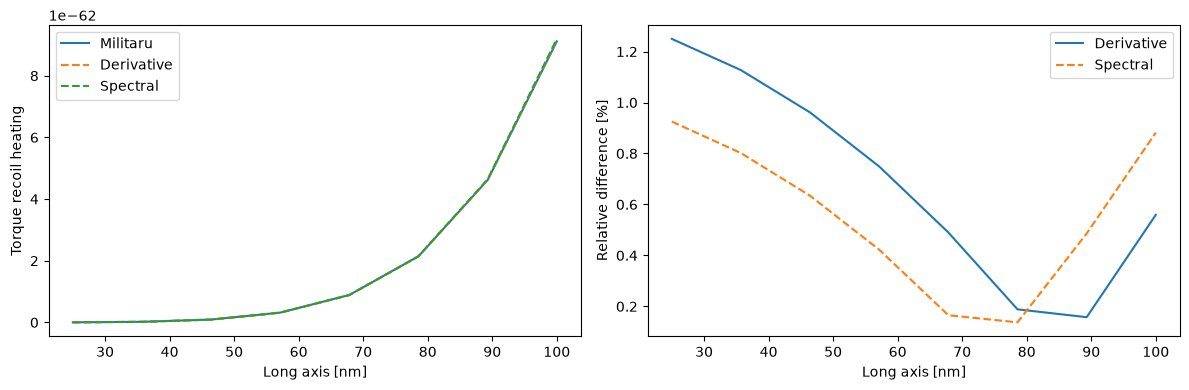

In [39]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

x = theoretical_limit_data["long_axis_nm"]

ax[0].plot(x, theoretical_limit_data["militaru_S_tau_tau_N2_m2_per_Hz"], label="Militaru")
ax[0].plot(x, theoretical_limit_data["derivative_S_tau_tau_y_N2_m2_per_Hz"], linestyle="--", label="Derivative")
ax[0].plot(x, theoretical_limit_data["spectral_S_tau_tau_y_N2_m2_per_Hz"], linestyle="--", label="Spectral")
ax[0].set(xlabel="Long axis [nm]", ylabel="Torque recoil heating")
ax[0].legend()

ax[1].plot(x, theoretical_limit_data["relative_diff_derivative"], label="Derivative")
ax[1].plot(x, theoretical_limit_data["relative_diff_spectral"], linestyle="--", label="Spectral")
ax[1].set(xlabel="Long axis [nm]", ylabel="Relative difference [%]")
ax[1].legend()

fig.tight_layout()
plt.show()

# Compare both methods for every long axis 

In [41]:
methods_data = comparison_data[["long_axis_nm", "derivative_S_tau_tau_y_N2_m2_per_Hz", "spectral_S_tau_tau_y_N2_m2_per_Hz"]]
methods_data["sym_relative_diff"] = np.abs(methods_data["derivative_S_tau_tau_y_N2_m2_per_Hz"] - methods_data["spectral_S_tau_tau_y_N2_m2_per_Hz"]) / ((np.abs(methods_data["derivative_S_tau_tau_y_N2_m2_per_Hz"]) + np.abs(methods_data["spectral_S_tau_tau_y_N2_m2_per_Hz"])) / 2)

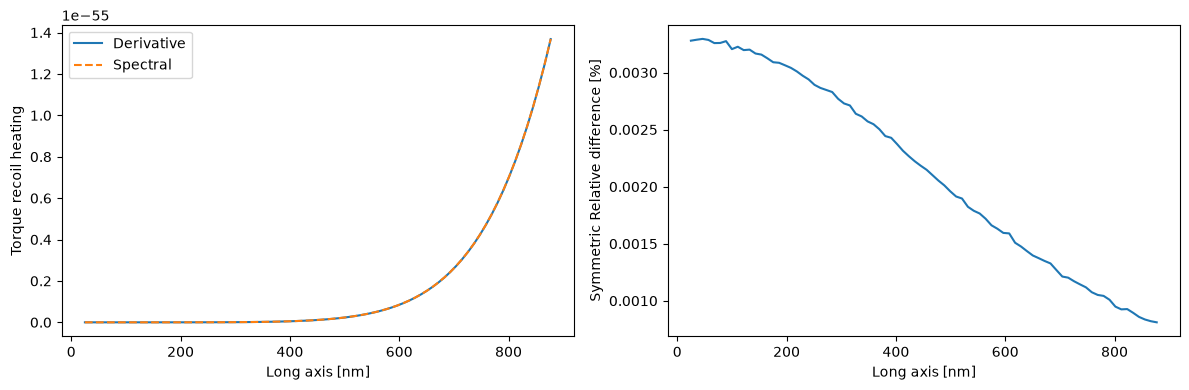

In [43]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

x = methods_data["long_axis_nm"]

ax[0].plot(x, methods_data["derivative_S_tau_tau_y_N2_m2_per_Hz"], label="Derivative")
ax[0].plot(x, methods_data["spectral_S_tau_tau_y_N2_m2_per_Hz"], linestyle="--", label="Spectral")
ax[0].set(xlabel="Long axis [nm]", ylabel="Torque recoil heating")
ax[0].legend()

ax[1].plot(x, methods_data["sym_relative_diff"])
ax[1].set(xlabel="Long axis [nm]", ylabel="Symmetric Relative difference [%]")

fig.tight_layout()
plt.show()

# Distribution of the channels

In [44]:
csv_files = sorted(csv_dir.glob("torque_component_distribution_case_*.csv"))
torque_component_data = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

In [50]:
components = torque_component_data.copy()

components["S0"] = components["spin_N2_m2_per_Hz"] + components["orbital_N2_m2_per_Hz"]
components["correlation_reduction"] = (-components["correlation_2mixed_N2_m2_per_Hz"]).clip(lower=0)
components["correlation_increase"] = components["correlation_2mixed_N2_m2_per_Hz"].clip(lower=0)

contribution_distribution = components.groupby(["long_axis_nm", "polarization"], as_index=False).agg(mean_S0=("S0", "mean"), mean_spin=("spin_N2_m2_per_Hz", "mean"), mean_orbital=("orbital_N2_m2_per_Hz", "mean"), mean_reduction=("correlation_reduction", "mean"), mean_increase=("correlation_increase", "mean"))

for name in ("spin", "orbital", "reduction", "increase"):
    contribution_distribution[f"{name}_percent"] = 100 * contribution_distribution[f"mean_{name}"] / contribution_distribution["mean_S0"]

contribution_distribution = contribution_distribution[["long_axis_nm", "polarization", "spin_percent", "orbital_percent", "reduction_percent", "increase_percent"]]

In [ ]:
terms = {"spin": "spin_N2_m2_per_Hz", "orbital": "orbital_N2_m2_per_Hz", "reduction": "correlation_reduction", "increase": "correlation_increase"}

valid_S0 = components["S0"].where(components["S0"] > 0)
for name, column in terms.items():
    components[f"{name}_direction_percent"] = 100 * components[column].div(valid_S0)

variances = components.groupby(["long_axis_nm", "polarization"], as_index=False).agg(**{f"{name}_variance": (f"{name}_direction_percent", "var") for name in terms})
contribution_distribution = contribution_distribution.merge(variances, on=["long_axis_nm", "polarization"])

In [60]:
contribution_distribution

,long_axis_nm,polarization,spin_percent,orbital_percent,reduction_percent,increase_percent,spin_variance,orbital_variance,reduction_variance,increase_variance
0,25.000000,LCP,49.940758,50.059242,95.979927,0.0,17.454432,17.454432,0.234829,0.0
1,25.000000,RCP,49.940758,50.059242,95.979927,0.0,17.454432,17.454432,0.234829,0.0
2,35.714286,LCP,49.939941,50.060059,95.973495,0.0,17.468961,17.468961,0.234293,0.0
3,35.714286,RCP,49.939941,50.060059,95.973495,0.0,17.468962,17.468962,0.234293,0.0
4,46.428571,LCP,49.938821,50.061179,95.964763,0.0,17.488617,17.488617,0.233562,0.0
...,...,...,...,...,...,...,...,...,...,...
155,855.533893,RCP,45.579704,54.420296,82.346640,0.0,31.150659,31.150659,10.637224,0.0
156,866.327234,LCP,45.418701,54.581299,81.963148,0.0,31.209352,31.209352,11.164051,0.0
157,866.327234,RCP,45.418701,54.581299,81.963148,0.0,31.209351,31.209351,11.164052,0.0
158,877.120575,LCP,45.254426,54.745574,81.577328,0.0,31.245756,31.245756,11.698704,0.0


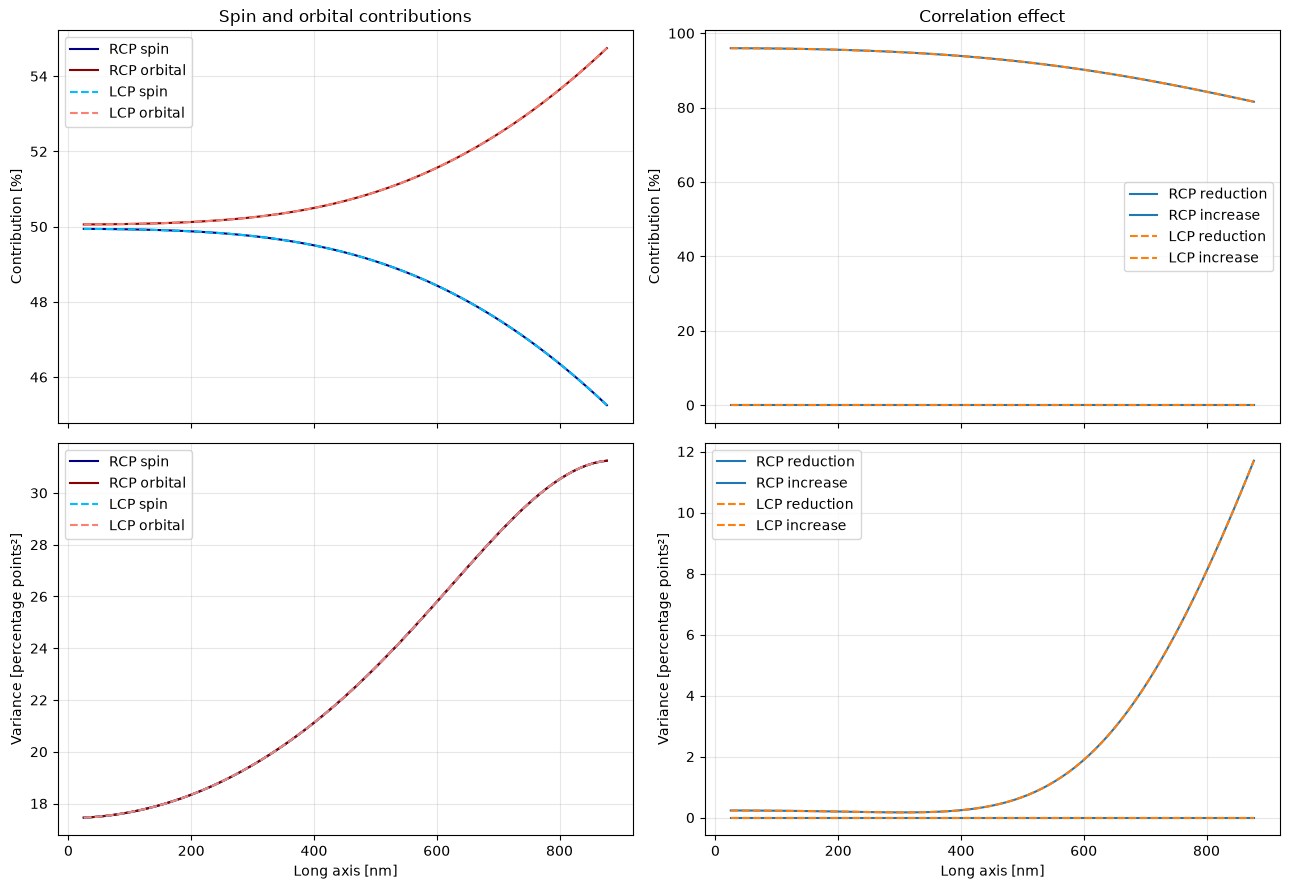

In [ ]:
spin_colors = {"RCP": "navy", "LCP": "deepskyblue"}
orbital_colors = {"RCP": "darkred", "LCP": "salmon"}
correlation_colors = {"RCP": "tab:blue", "LCP": "tab:orange"}

fig, ax = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

for polarization in ("RCP", "LCP"):
    data = contribution_distribution[contribution_distribution["polarization"] == polarization].sort_values("long_axis_nm")
    x = data["long_axis_nm"]
    line_style = "--" if polarization == "LCP" else "-"

    ax[0, 0].plot(x, data["spin_percent"], color=spin_colors[polarization], linestyle=line_style, label=f"{polarization} spin")
    ax[0, 0].plot(x, data["orbital_percent"], color=orbital_colors[polarization], linestyle=line_style, label=f"{polarization} orbital")

    ax[0, 1].plot(x, data["reduction_percent"], color=correlation_colors[polarization], linestyle=line_style, label=f"{polarization} reduction")
    ax[0, 1].plot(x, data["increase_percent"], color=correlation_colors[polarization], linestyle=line_style, label=f"{polarization} increase")

    ax[1, 0].plot(x, data["spin_variance"], color=spin_colors[polarization], linestyle=line_style, label=f"{polarization} spin")
    ax[1, 0].plot(x, data["orbital_variance"], color=orbital_colors[polarization], linestyle=line_style, label=f"{polarization} orbital")

    ax[1, 1].plot(x, data["reduction_variance"], color=correlation_colors[polarization], linestyle=line_style, label=f"{polarization} reduction")
    ax[1, 1].plot(x, data["increase_variance"], color=correlation_colors[polarization], linestyle=line_style, label=f"{polarization} increase")

ax[0, 0].set(title="Spin and orbital contributions", ylabel="Contribution [%]")
ax[0, 1].set(title="Correlation effect", ylabel="Contribution [%]")
ax[1, 0].set(xlabel="Long axis [nm]", ylabel="Variance [percentage points²]")
ax[1, 1].set(xlabel="Long axis [nm]", ylabel="Variance [percentage points²]")

for axis in ax.flat:
    axis.legend()
    axis.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [62]:
output_dir = Path("outputs/recoil_heatings_results")
output_dir.mkdir(parents=True, exist_ok=True)

for name in ("theoretical_limit_data", "methods_data", "contribution_distribution"):
    globals()[name].to_csv(output_dir / f"{name}.csv", index=False)